Loaded results_summary_all.csv  (20 rows)
Saved  heatmap_document.pdf  +  heatmap_document.png


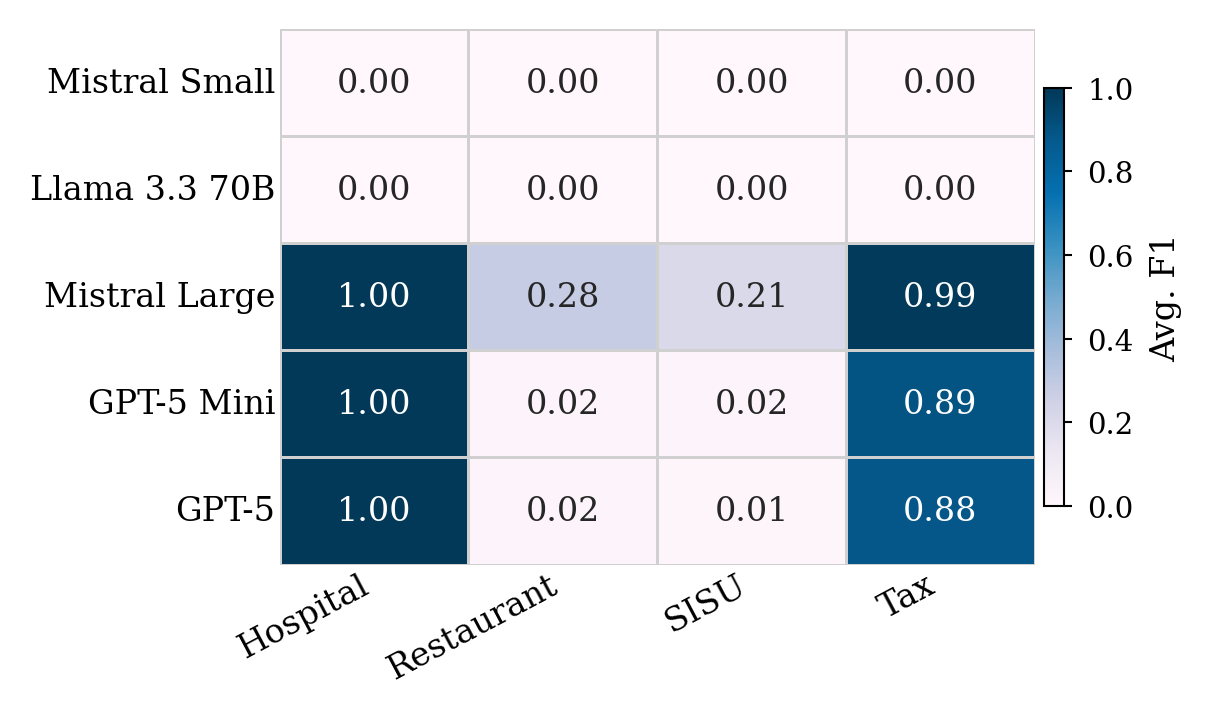

In [13]:
"""
heatmap_publication.py
======================
Publication-ready heatmap: violation detection F1 by model × dataset.
Drop-in replacement for the "document mode" snippet — same spirit as the
multi-implementation grid, but for a single implementation / single metric.

Usage
-----
1. Set CSV_PATH to your results file (must contain columns:
       model, dataset, aggregate_violation_f1)
2. Run:  python heatmap_publication.py
Outputs: heatmap_document.pdf  +  heatmap_document.png
"""

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

CSV_PATH = "results_summary_all.csv"

df = pd.read_csv(CSV_PATH)
print(f"Loaded {CSV_PATH}  ({len(df)} rows)")

# ── 1. Display names & orderings ──────────────────────────────────────────────
model_display = {
    "mistral-small-2506":      "Mistral Small",
    "mistral-large-2512":      "Mistral Large",
    "gpt-5-mini":              "GPT-5 Mini",
    "gpt-5":                   "GPT-5",
    "llama-3.3-70b-versatile": "Llama 3.3 70B",
}
dataset_display = {
    "hospital":   "Hospital",
    "restaurant": "Restaurant",
    "sisu":       "SISU",
    "tax":        "Tax",
}
# Row order: weakest → strongest (visual narrative)
model_order = [
    "mistral-small-2506",
    "llama-3.3-70b-versatile",
    "mistral-large-2512",
    "gpt-5-mini",
    "gpt-5",
]
dataset_order = ["hospital", "restaurant", "sisu", "tax"]

ordered_models = [model_display[m] for m in model_order if m in model_display]
ordered_datasets = [dataset_display[d] for d in dataset_order if d in dataset_display]

# ── 2. Publication-style rcParams ─────────────────────────────────────────────
mpl.rcParams.update({
    "font.family":        "serif",
    "font.size":          9,
    "axes.titlesize":     10,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "text.usetex":        False,   # flip to True when LaTeX is available
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.6,
    "ytick.major.width":  0.6,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
})

CMAP = "PuBu"
METRIC = "aggregate_violation_f1"
TITLE = "DOCUMENT mode — violation detection by model and dataset"

# ── 3. Build heat matrix ───────────────────────────────────────────────────────
df["model_d"] = df["model"].map(model_display)
df["dataset_d"] = df["dataset"].map(dataset_display)

heat_data = (
    df.groupby(["model_d", "dataset_d"])[METRIC]
    .mean()
    .unstack("dataset_d")
    .reindex(index=ordered_models, columns=ordered_datasets)
)

def _fmt(v):
    return f"{v:.2f}" if not pd.isna(v) else "—"

annot = heat_data.apply(lambda col: col.map(_fmt))

# ── 4. Figure layout (tightened for paper proportions) ───────────────────────
n_rows = len(ordered_models)
n_cols = len(ordered_datasets)

fig_w = 0.70 + n_cols * 0.88
fig_h = 0.45 + n_rows * 0.42

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.subplots_adjust(left=0.22, right=0.93, top=0.88, bottom=0.18)

# ── 5. Heatmap ────────────────────────────────────────────────────────────────
sns.heatmap(
    heat_data,
    ax=ax,
    annot=annot,
    fmt="",
    cmap=CMAP,
    vmin=0.0,
    vmax=1.0,
    linewidths=0.30,
    linecolor="#d0d0d0",
    cbar=True,
    cbar_kws={"shrink": 0.78, "pad": 0.01, "aspect": 20},
    xticklabels=True,
    yticklabels=True,
    annot_kws={"size": 8.0, "family": "serif"},
)

# ── 6. Colour-bar cosmetics ───────────────────────────────────────────────────
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=7, length=2, width=0.5)
cbar.set_label("Avg. F1", size=8, labelpad=4)
cbar.outline.set_linewidth(0.5)

# ── 7. Axis labels & ticks ────────────────────────────────────────────────────
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(ax.get_xticklabels(), rotation=28, ha="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
ax.tick_params(length=0, pad=1)

# # ── 8. Title ──────────────────────────────────────────────────────────────────
# ax.set_title(
#     TITLE,
#     fontsize=9,
#     fontstyle="italic",
#     pad=4,
#     loc="left",
#     x=-0.01,
# )

# ── 9. Save ──────────────────────────────────────────────────────────────────
fig.savefig("heatmap_document.pdf", format="pdf")
fig.savefig("heatmap_document.png", format="png")
print("Saved  heatmap_document.pdf  +  heatmap_document.png")
plt.show()